# Supplementary Figure S6 — robustness and longitudinal evidence

Live, repository-relative plotting from checksummed plot-ready data. Statistical derivation is isolated under `Figure_6/analysis/`.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import hashlib
import matplotlib.pyplot as plt
from plotting import *
ROOT=Path.cwd(); DATA_ROOT=ROOT/'data'; OUTPUT_ROOT=ROOT/'outputs'; PANEL_ROOT=OUTPUT_ROOT/'panels'


In [2]:
DATA=load_tables(DATA_ROOT,SUPPLEMENT_INPUTS)
print(f'Loaded {len(DATA)} checksummed plot-ready tables from data/')

Loaded 14 checksummed plot-ready tables from data/


## Standalone panels

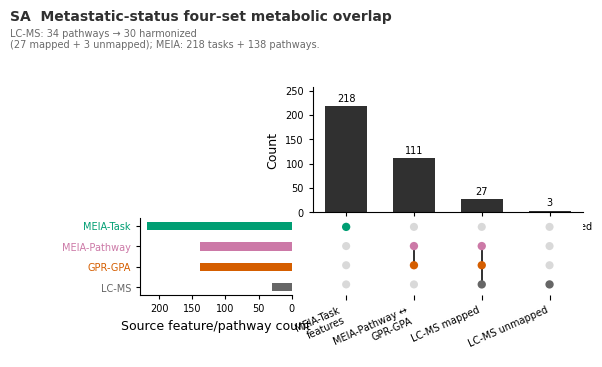

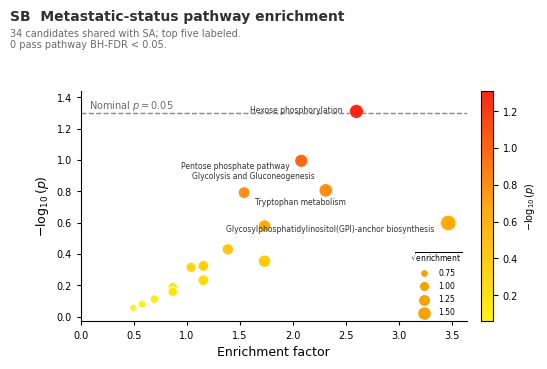

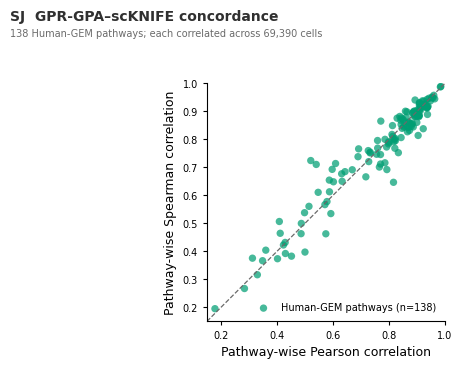

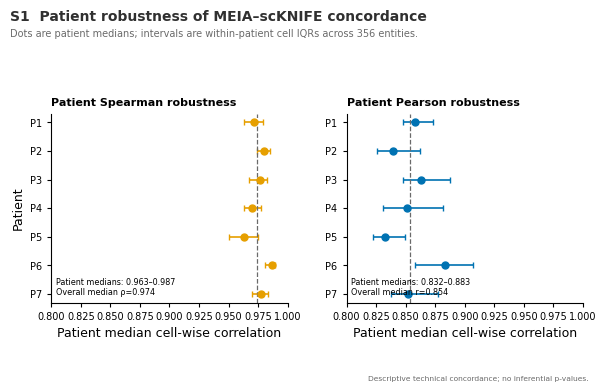

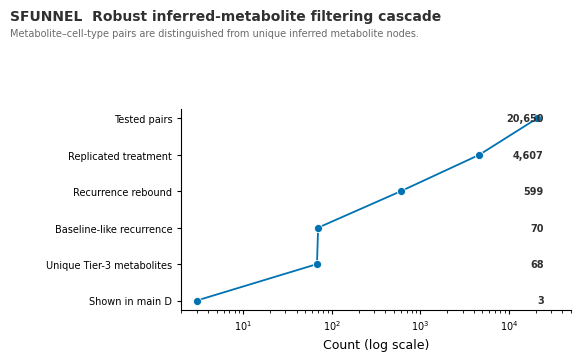

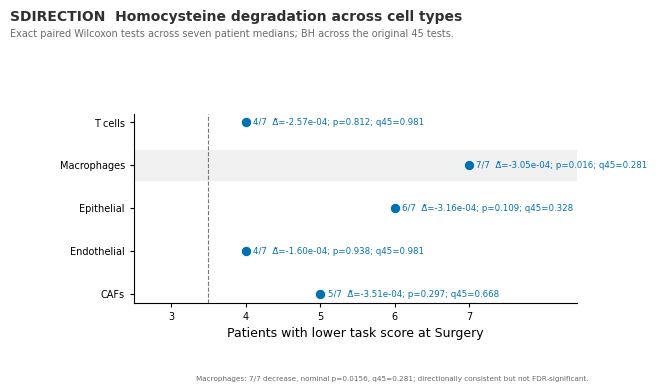

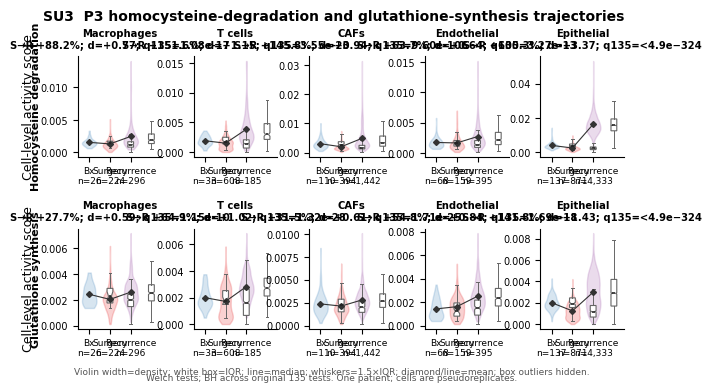

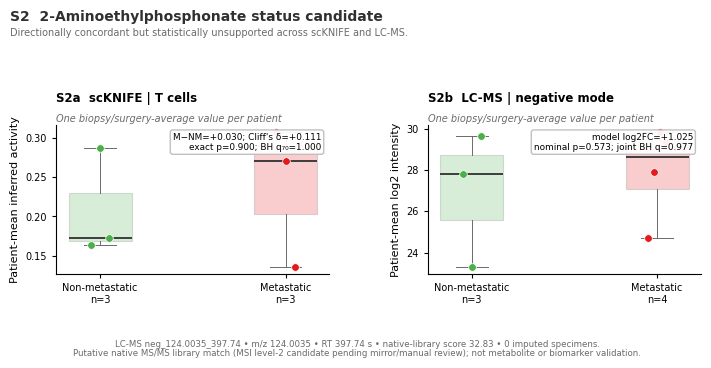

3831

In [3]:
panel_manifest={'figure':'Figure S6','panel_order':['SA', 'SB', 'SJ', 'S1', 'SFUNNEL', 'SDIRECTION', 'SU3', 'S2'],'formats':['png','pdf'],'png_dpi':300,'note':'Standalone exports generated by the authoritative plotting-only notebook.','panels':{}}
for label in ['SA', 'SB', 'SJ', 'S1', 'SFUNNEL', 'SDIRECTION', 'SU3', 'S2']:
    fig=make_figure6_supplementary_panel(label,DATA)
    save_figure(fig,PANEL_ROOT/f'Figure_S6_{label}')
    panel_manifest['panels'][label]={}
    for ext in ('png','pdf'):
        path=PANEL_ROOT/f'Figure_S6_{label}.{ext}'; rel=path.relative_to(ROOT.parent if "Figure_S6"=="Figure_6" else ROOT.parents[1])
        panel_manifest['panels'][label][ext]={'path':str(rel),'bytes':path.stat().st_size,'sha256':hashlib.sha256(path.read_bytes()).hexdigest()}
    plt.show();plt.close(fig)
(PANEL_ROOT/'Figure_S6_panel_export_manifest.json').write_text(json.dumps(panel_manifest,indent=2)+'\n')

## Compiled vector figure

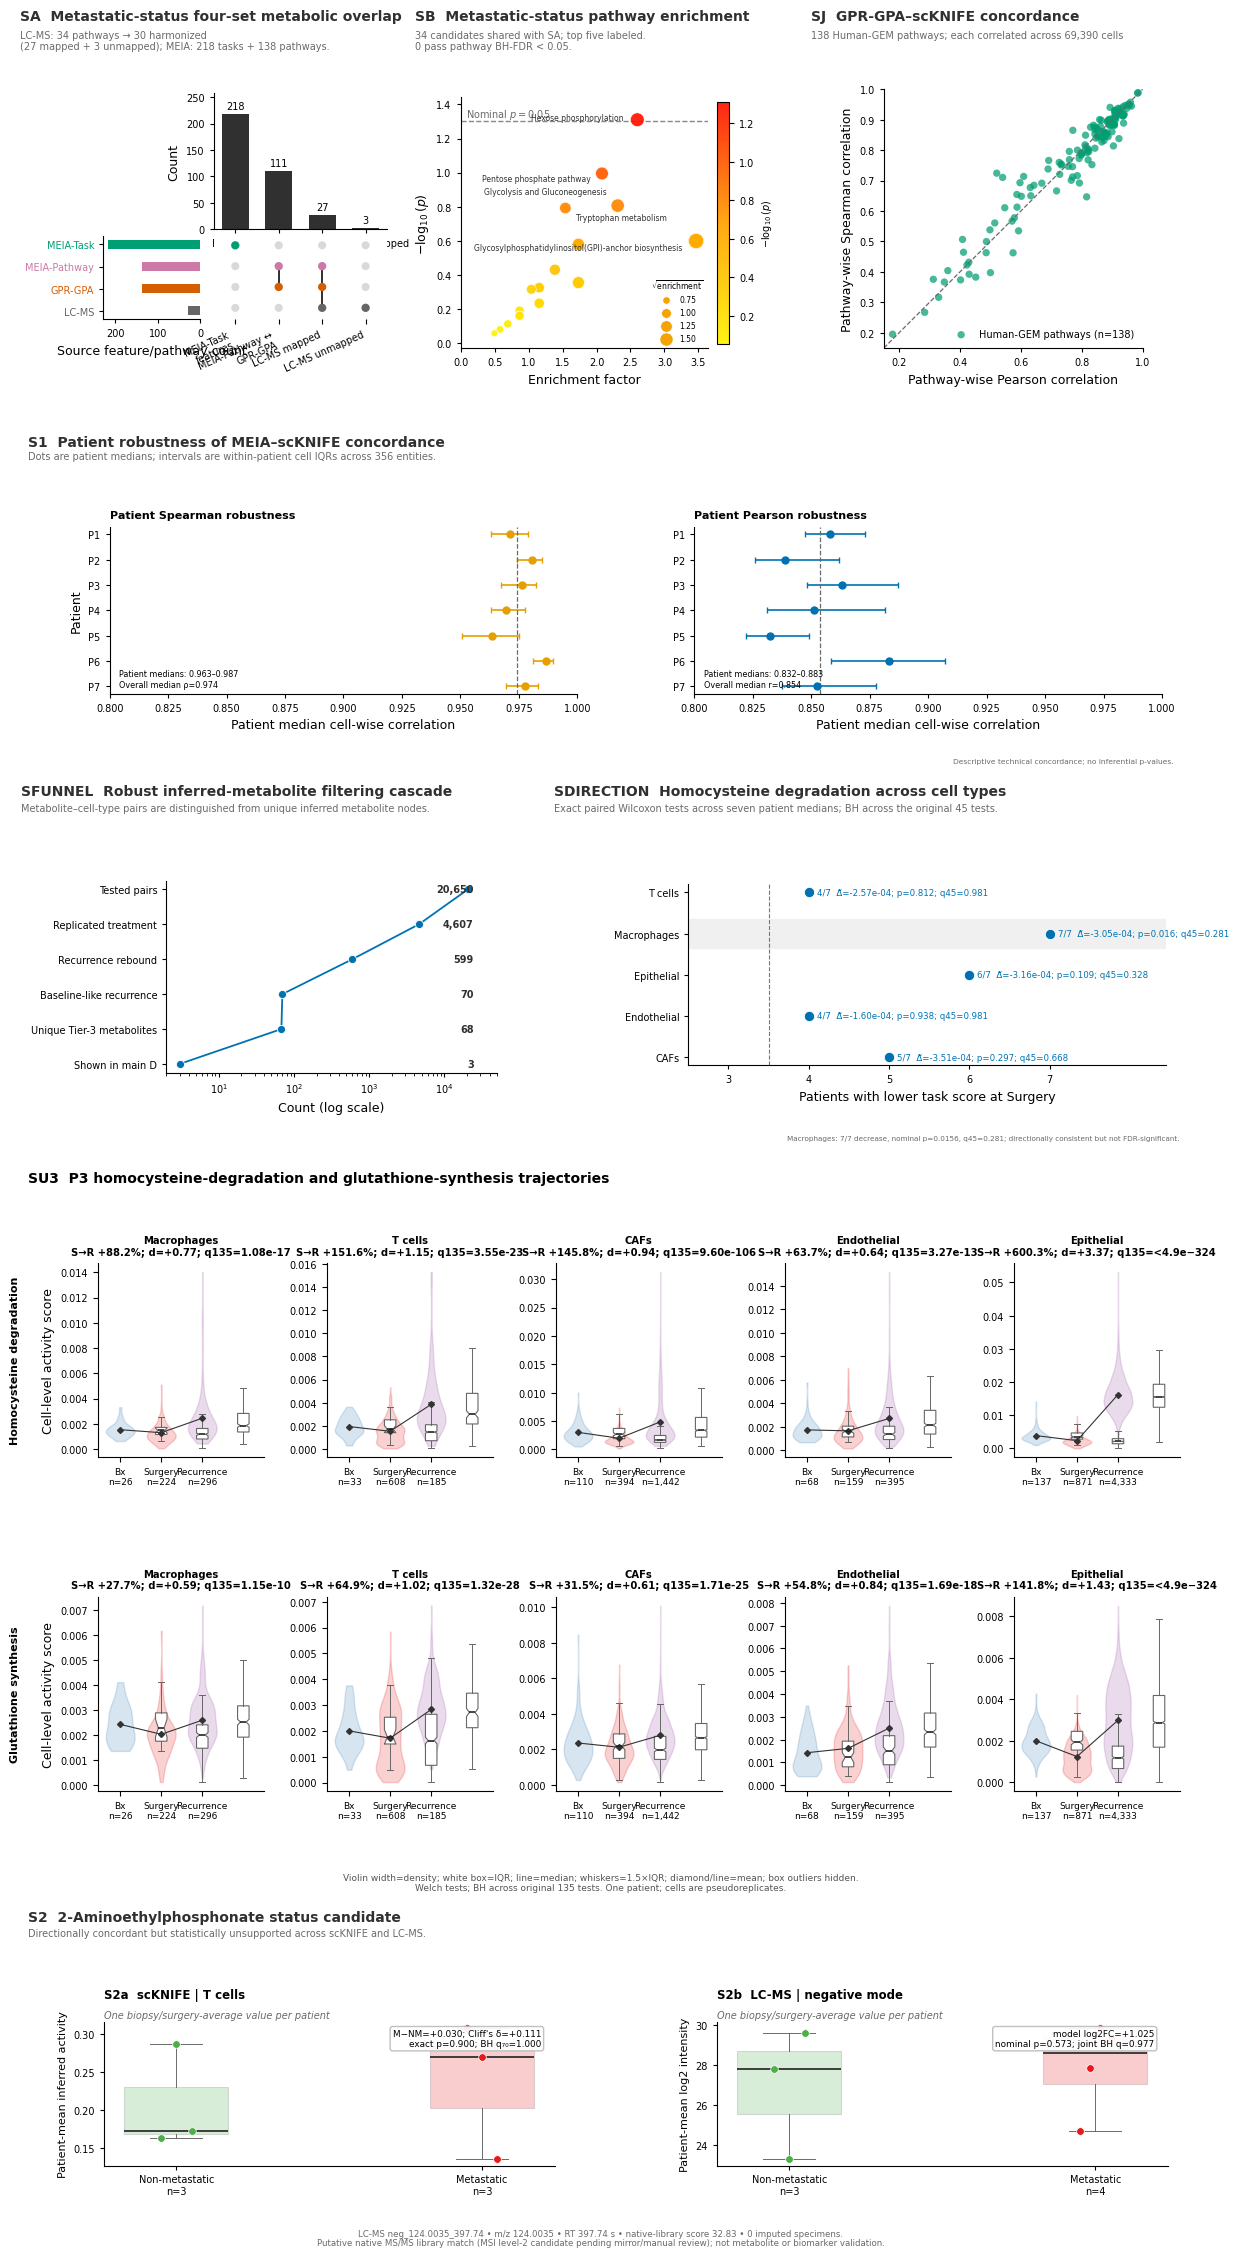

In [4]:
fig=make_figure6_supplementary(DATA)
save_figure(fig,OUTPUT_ROOT/'Figure_S6')
compiled_png=OUTPUT_ROOT/'Figure_S6.png'
preview_png=OUTPUT_ROOT/'Figure_S6_preview.png'
preview_png.write_bytes(compiled_png.read_bytes())
assert preview_png.read_bytes()==compiled_png.read_bytes()
plt.show();plt.close(fig)